# 01 - Scenario di riferimento e verifica nominale (adult#001)

**Obiettivo.** Definire lo scenario di riferimento, verificare che l'anello di controllo sia stabile in condizioni nominali (a digiuno) e osservare la risposta a un pasto non annunciato da 60 g.

**Controllori** (codice in `aid_sim.py`):
1. **PID**: regolatore ad azione diretta `u = u_b + Kp e + Ki I + Kd de/dt`, con anti-windup per clamping dell'integrale e saturazione `0 <= u <= 0.25 U/min`.
2. **PID + IOB + PLGS** (proposto): stesso PID, con in più un tetto sull'insulina attiva stimata `IOB = S1 + S2` e la sospensione predittiva dell'infusione (PLGS).

**Metriche** (sulla glicemia plasmatica): TIR (70-180 mg/dL), TAR (>180 e >250), TBR (<70 e <54), picco, nadir, TBR tardivo (da 3 ore dopo il pasto a fine simulazione).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 110)
SEED = 1                      # seme del rumore del sensore (uguale per tutti i controllori)
PID  = {}                     # PID di riferimento: parametri di default di AIDController
PROP = dict(use_iob=True, use_plgs=True)   # controllore proposto: stesso PID + tetto IOB + PLGS
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.12.3
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


## 1. Configurazione
### 1.1 Scenario: condizioni iniziali, durata, passo, pasto, seme

In [2]:
PAZIENTE = 'adult#001'
ub = U.initial_conditions(PAZIENTE, SEED)['ub']
display(U.scenario_table(PAZIENTE, 60.0, SEED))

,Voce,Valore,Unita'
0,Paziente virtuale,adult#001,-
1,Peso corporeo BW,102.3,kg
2,Glicemia basale di equilibrio Gb,138.6,mg/dL
3,Fabbisogno basale nominale u_b,1.267,U/h
4,Sensore CGM,Dexcom (rumore autoregressivo UVA/Padova),-
5,Pompa di infusione,Insulet,-
6,Seme casuale sensore (seed),1,-
7,Inizio simulazione,08:00,ora solare
8,Durata simulazione,16.0,h
9,Passo di campionamento dt,3.0,min


### 1.2 Parametri e vincoli dei controllori (con unità di misura)
Il PID di riferimento non ha tetto IOB né PLGS; il proposto li attiva. Tutti gli altri parametri sono identici.

In [3]:
print("PID di riferimento"); display(U.controller_table(PID, ub))
print("PID + IOB + PLGS (proposto)"); display(U.controller_table(PROP, ub))

PID di riferimento


,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.000005,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM (segno positivo)
4,i_min,-2000.0,mg*min/dL,Limite inferiore anti-windup (clamping)
5,i_max,10000.0,mg*min/dL,Limite superiore anti-windup (clamping)
6,use_iob,False,-,Attiva il vincolo dinamico sull'insulina attiva (IOB)
7,iob_alpha,1.5,adimensionale,Fattore di scala: tetto IOB = iob_alpha * basale orario
8,tau_s,50.0,min,Costante di tempo dei compartimenti sottocutanei IOB
9,use_plgs,False,-,Attiva la sospensione predittiva dell'infusione (PLGS)


PID + IOB + PLGS (proposto)


,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.000005,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM (segno positivo)
4,i_min,-2000.0,mg*min/dL,Limite inferiore anti-windup (clamping)
5,i_max,10000.0,mg*min/dL,Limite superiore anti-windup (clamping)
6,use_iob,True,-,Attiva il vincolo dinamico sull'insulina attiva (IOB)
7,iob_alpha,1.5,adimensionale,Fattore di scala: tetto IOB = iob_alpha * basale orario
8,tau_s,50.0,min,Costante di tempo dei compartimenti sottocutanei IOB
9,use_plgs,True,-,Attiva la sospensione predittiva dell'infusione (PLGS)


### 1.3 Unità di misura delle variabili di uscita
| Variabile | Unità |
|---|---|
| `t_h` | ore dall'inizio della simulazione (0 = 08:00) |
| `CGM`, `BG` | mg/dL (misura del sensore, glicemia plasmatica) |
| `Insulin_Uh` | U/h (velocità di infusione) |
| `IOB` | U (insulina sottocutanea stimata non ancora assorbita) |

## 2. Verifica nominale a digiuno (0 g)
Senza pasto la glicemia deve restare stabile e nell'intervallo target, per entrambi i controllori.

,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,picco,nadir
0,PID,100.0,0.0,0.0,0.0,0.0,138.6,85.2
1,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,138.6,92.4


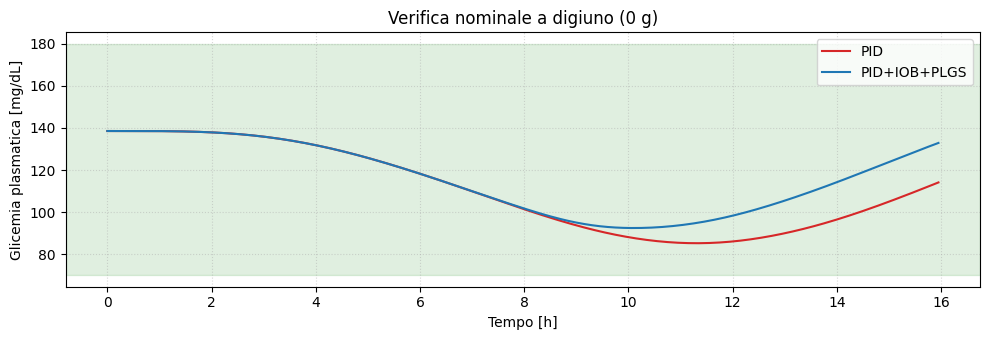

In [4]:
res0 = {n: A.simulate(PAZIENTE, 0.0, kw, seed=SEED)[0] for n, kw in [('PID', PID), ('PID+IOB+PLGS', PROP)]}
rows = []
for n, df in res0.items():
    m = A.metrics(df); rows.append({'Controllore': n, **{k: round(float(v), 1) for k, v in m.items() if k != 'TBR_tardivo'}})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(figsize=(10, 3.5))
for n, c in [('PID', 'tab:red'), ('PID+IOB+PLGS', 'tab:blue')]: ax.plot(res0[n].t_h, res0[n].BG, color=c, label=n)
ax.axhspan(70, 180, color='green', alpha=.12); ax.set_xlabel('Tempo [h]'); ax.set_ylabel('Glicemia plasmatica [mg/dL]')
ax.set_title('Verifica nominale a digiuno (0 g)'); ax.legend(); ax.grid(ls=':', alpha=.5); plt.tight_layout(); plt.show()

## 3. Pasto non annunciato da 60 g alle 12:00

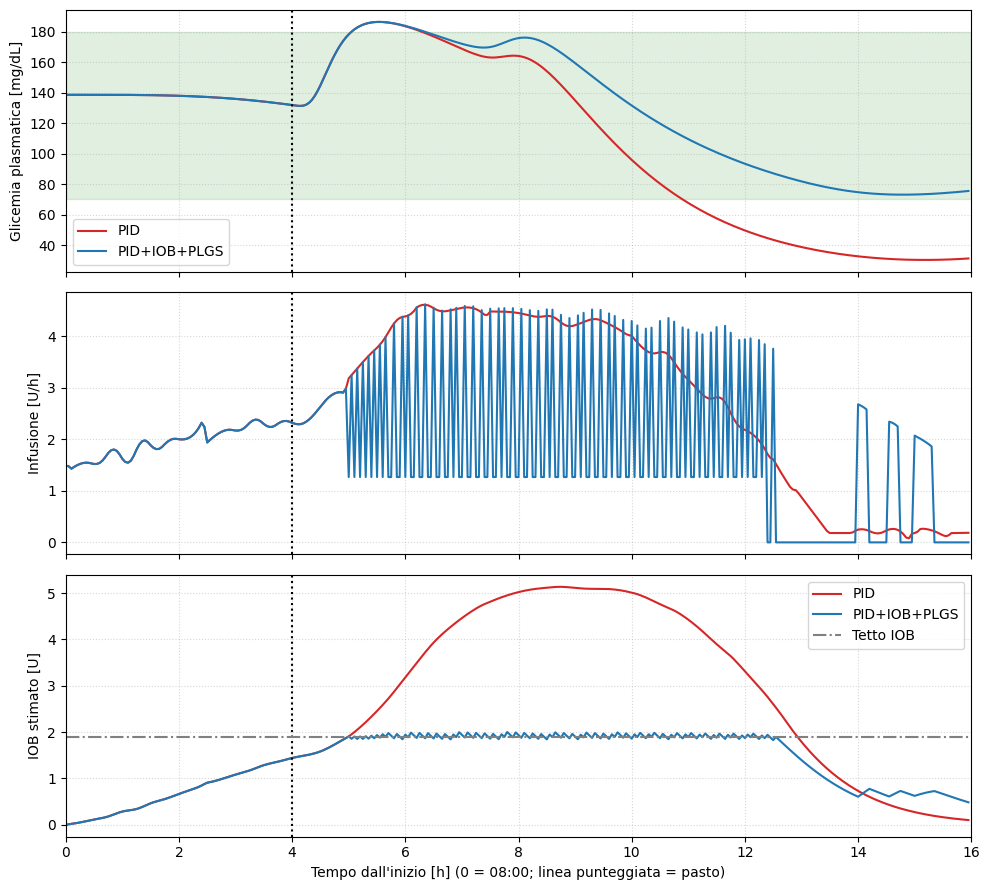

In [5]:
res = {n: A.simulate(PAZIENTE, 60.0, kw, seed=SEED)[0] for n, kw in [('PID', PID), ('PID+IOB+PLGS', PROP)]}
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for n, c in [('PID', 'tab:red'), ('PID+IOB+PLGS', 'tab:blue')]:
    ax[0].plot(res[n].t_h, res[n].BG, color=c, label=n); ax[1].plot(res[n].t_h, res[n].Insulin_Uh, color=c); ax[2].plot(res[n].t_h, res[n].IOB, color=c, label=n)
for a in ax: a.axvline(A.MEAL_OFFSET_H, color='k', ls=':'); a.grid(ls=':', alpha=.5)
ax[0].axhspan(70, 180, color='green', alpha=.12); ax[0].set_ylabel('Glicemia plasmatica [mg/dL]'); ax[0].legend()
ax[1].set_ylabel('Infusione [U/h]'); ax[2].axhline(1.5*ub*60, color='gray', ls='-.', label='Tetto IOB'); ax[2].set_ylabel('IOB stimato [U]'); ax[2].legend()
ax[2].set_xlabel("Tempo dall'inizio [h] (0 = 08:00; linea punteggiata = pasto)"); ax[2].set_xlim(0, 16); plt.tight_layout(); plt.show()

In [6]:
rows = []
for n, df in res.items():
    m = A.metrics(df); rows.append({'Controllore': n, **{k: round(float(v), 1) for k, v in m.items()}})
display(pd.DataFrame(rows))

,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,picco,nadir
0,PID,60.6,7.5,0.0,31.9,26.6,56.7,186.3,30.4
1,PID+IOB+PLGS,92.2,7.8,0.0,0.0,0.0,0.0,186.3,73.1


## 4. Lettura dei risultati
Il picco postprandiale è quasi identico per i due controllori: con i ritardi di misura e di assorbimento dell'insulina nessuno dei due può evitarlo. La differenza compare dopo, quando il PID accumula insulina nel sottocute (IOB elevato) e va in ipoglicemia, mentre il tetto sull'IOB la limita. Il tetto agisce come un interruttore (l'infusione alterna tra valore basale e valore alto): è un limite da discutere nella tesi.